In [1]:
import sys
from google.colab import drive

drive.mount('/content/drive')
sys.path.insert(0, '/content/drive/MyDrive/predictive_learning')

import networks
from networks import LateralInhibitoryLayer
import generators
from generators import MovingMNIST32
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output



def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

ValueError: mount failed

# CATCAM dataset (16x16 whitened on/off patches)

Natural videos, taken by a camera attached to a cat's head (https://pubmed.ncbi.nlm.nih.gov/14762723/). We extract a patch, whiten it with ZCA and split it into on off channels

In [ ]:
import os
import glob
import re
import numpy as np
from PIL import Image

class CatCamVideoPatchGenerator:
    def __init__(self, dataset_dir='/content/drive/MyDrive/data/catcam_dataset/cat01/labelb000530a', patch_size=16, num_whitening_samples=10000):
        self.patch_size = patch_size

        # Find and sort frame files
        frame_files = glob.glob(os.path.join(dataset_dir, "*.tif"))
        def extract_frame_number(filename):
            match = re.search(r'Catt(\d+)\.tif', filename)
            return int(match.group(1)) if match else 0
        self.frame_files = sorted(frame_files, key=extract_frame_number)

        if not self.frame_files:
            raise ValueError(f"No .tif frame files found in {dataset_dir}")

        # Load all frames into memory
        print(f"Loading {len(self.frame_files)} frames...")
        self.frames = []
        for path in self.frame_files:
            with Image.open(path) as img:
                self.frames.append(np.array(img, dtype=np.float32))
        self.frames = np.array(self.frames)
        self.num_frames, self.h, self.w = self.frames.shape

        # Initialize frame index and patch position
        self.current_frame_idx = 0
        self.current_y = (self.h - self.patch_size) // 2
        self.current_x = (self.w - self.patch_size) // 2

        # Parameters to store whitening statistics
        self.mean = None
        self.whitening_matrix = None

        # Fit ZCA Whitening on sampled patches
        self.fit_whitening(num_whitening_samples)

    def fit_whitening(self, num_samples):
        print(f"Extracting {num_samples} patches to fit whitening transform...")
        patches = []
        for _ in range(num_samples):
            f_idx = np.random.randint(0, self.num_frames)
            y = np.random.randint(0, self.h - self.patch_size)
            x = np.random.randint(0, self.w - self.patch_size)
            patch = self.frames[f_idx, y:y+self.patch_size, x:x+self.patch_size]
            patches.append(patch.flatten())
        patches = np.array(patches)

        # Calculate mean and covariance for ZCA Whitening
        self.mean = np.mean(patches, axis=0)
        patches_centered = patches - self.mean
        cov = np.cov(patches_centered, rowvar=False)

        # Eigendecomposition
        U, S, V_t = np.linalg.svd(cov)
        epsilon = 1e-5
        # ZCA Whitening matrix: U * diag(1/sqrt(S + epsilon)) * U^T
        self.whitening_matrix = U @ np.diag(1.0 / np.sqrt(S + epsilon)) @ U.T
        print("Whitening transformation fitted successfully.")

    def set_position(self, y, x, frame_idx=0):
        """Set the coordinate window position and frame index."""
        self.current_y = np.clip(y, 0, self.h - self.patch_size)
        self.current_x = np.clip(x, 0, self.w - self.patch_size)
        self.current_frame_idx = frame_idx % self.num_frames

    def set_next_position(self):
        """Advance the video to the next frame."""
        self.current_frame_idx = (self.current_frame_idx + 1) % self.num_frames

    def get_current_frame(self):
        """Extract, whiten, and split the current patch into ON/OFF channels."""
        # 1. Extract raw patch
        patch = self.frames[
            self.current_frame_idx,
            self.current_y : self.current_y + self.patch_size,
            self.current_x : self.current_x + self.patch_size
        ]

        # 2. Whiten the patch using the pre-fitted parameters
        flat_patch = patch.flatten() - self.mean
        whitened_flat = flat_patch @ self.whitening_matrix.T
        whitened_patch = whitened_flat.reshape(self.patch_size, self.patch_size)

        # 3. Split into ON and OFF channels
        on_channel = np.maximum(0, whitened_patch)
        off_channel = np.maximum(0, -whitened_patch)

        # Return as (2, patch_size, patch_size) array
        return np.stack([on_channel, off_channel], axis=0)

In [ ]:
import os
import glob
import re
import numpy as np
from PIL import Image

class CatCamVideoPatchGenerator:
    def __init__(self, dataset_dir='/content/drive/MyDrive/data/catcam_dataset/cat01/labelb000530a', patch_size=16, num_whitening_samples=10000):
        self.patch_size = patch_size

        # Find and sort frame files
        frame_files = glob.glob(os.path.join(dataset_dir, "*.tif"))
        def extract_frame_number(filename):
            match = re.search(r'Catt(\d+)\.tif', filename)
            return int(match.group(1)) if match else 0
        self.frame_files = sorted(frame_files, key=extract_frame_number)

        if not self.frame_files:
            raise ValueError(f"No .tif frame files found in {dataset_dir}")

        # Load all frames into memory
        print(f"Loading {len(self.frame_files)} frames...")
        self.frames = []
        for path in self.frame_files:
            with Image.open(path) as img:
                self.frames.append(np.array(img, dtype=np.float32))
        self.frames = np.array(self.frames)
        self.num_frames, self.h, self.w = self.frames.shape

        # Initialize frame index and patch position
        self.current_frame_idx = 0
        self.current_y = (self.h - self.patch_size) // 2
        self.current_x = (self.w - self.patch_size) // 2

        # Parameters to store whitening parameters
        self.mean = None
        self.whitening_matrix = None

        # Fit ZCA Whitening on sampled patches
        self.fit_whitening(num_whitening_samples)

    def fit_whitening(self, num_samples):
        print(f"Extracting {num_samples} patches to fit whitening transform...")
        patches = []
        for _ in range(num_samples):
            f_idx = np.random.randint(0, self.num_frames)
            y = np.random.randint(0, self.h - self.patch_size)
            x = np.random.randint(0, self.w - self.patch_size)
            patch = self.frames[f_idx, y:y+self.patch_size, x:x+self.patch_size]
            patches.append(patch.flatten())
        patches = np.array(patches)

        # Calculate mean and covariance for ZCA Whitening
        self.mean = np.mean(patches, axis=0)
        patches_centered = patches - self.mean
        cov = np.cov(patches_centered, rowvar=False)

        # Eigendecomposition
        U, S, V_t = np.linalg.svd(cov)
        epsilon = 1e-5
        # ZCA Whitening matrix: U * diag(1/sqrt(S + epsilon)) * U^T
        self.whitening_matrix = U @ np.diag(1.0 / np.sqrt(S + epsilon)) @ U.T
        print("Whitening transformation fitted successfully.")

    def set_position(self, y, x, frame_idx=0):
        """Set the coordinate window position and frame index."""
        self.current_y = np.clip(y, 0, self.h - self.patch_size)
        self.current_x = np.clip(x, 0, self.w - self.patch_size)
        self.current_frame_idx = frame_idx % self.num_frames

    def set_next_position(self):
        """Advance the video to the next frame."""
        self.current_frame_idx = (self.current_frame_idx + 1) % self.num_frames

    def get_current_frame(self):
        """Extract, whiten, and split the current patch into ON/OFF channels."""
        # 1. Extract raw patch
        patch = self.frames[
            self.current_frame_idx,
            self.current_y : self.current_y + self.patch_size,
            self.current_x : self.current_x + self.patch_size
        ]

        # 2. Whiten the patch using the pre-fitted parameters
        flat_patch = patch.flatten() - self.mean
        whitened_flat = flat_patch @ self.whitening_matrix.T
        whitened_patch = whitened_flat.reshape(self.patch_size, self.patch_size)

        # 3. Split into ON and OFF channels
        on_channel = np.maximum(0, whitened_patch)
        off_channel = np.maximum(0, -whitened_patch)

        # Return as (2, patch_size, patch_size) array
        return np.stack([on_channel, off_channel], axis=0)


Loading 2012 frames...
Extracting 1000 patches to fit whitening transform...
Whitening transformation fitted successfully.


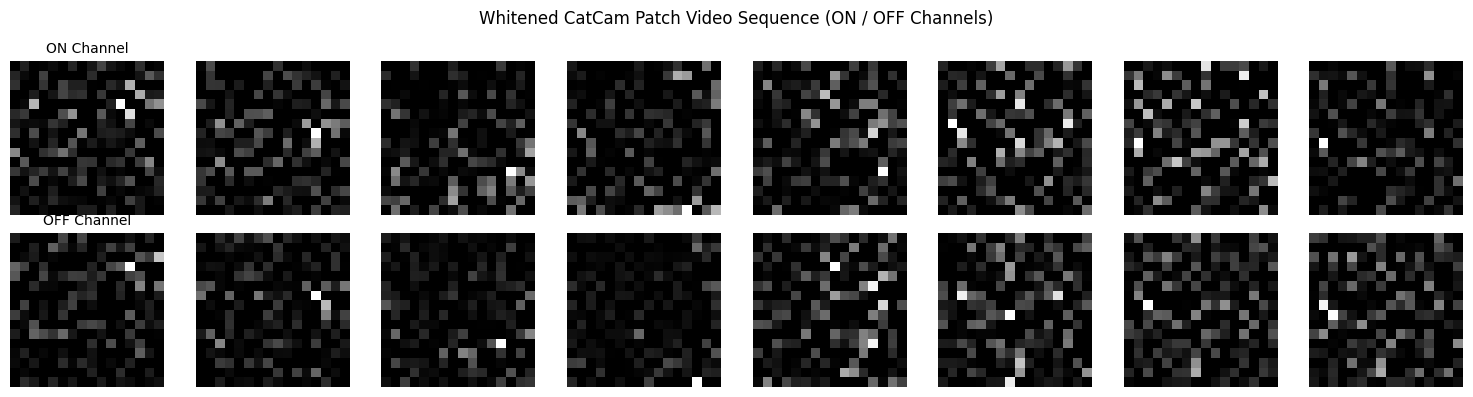

In [ ]:
# Instantiate the generator
generator = CatCamVideoPatchGenerator(
    dataset_dir='/content/drive/MyDrive/data/catcam_dataset/cat01/labelb000530a',
    patch_size=16,
    num_whitening_samples=1000
)

# Set the patch coordinate (e.g., center of the image)
generator.set_position(y=100, x=150, frame_idx=0)

# Extract and visualize a short sequence of 8 frames
fig, axes = plt.subplots(2, 8, figsize=(15, 4))
for i in range(8):
    frame_channels = generator.get_current_frame() # shape: (2, 16, 16)
    on_channel = frame_channels[0]
    off_channel = frame_channels[1]

    axes[0, i].imshow(on_channel, cmap='gray')
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_title("ON Channel", fontsize=10)

    axes[1, i].imshow(off_channel, cmap='gray')
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_title("OFF Channel", fontsize=10)

    # Move to the next frame in the sequence
    generator.set_next_position()

plt.suptitle("Whitened CatCam Patch Video Sequence (ON / OFF Channels)")
plt.tight_layout()
plt.show()